# Density-Based Clustering and Association Rule Mining: DBSCAN clustering, noise point detection, Apriori algorithm and association rule generation

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

In [23]:
# Load dataset
df = pd.read_csv('OnlineRetail.csv', encoding='latin1')

In [24]:
# Select numerical columns
X = df[['Quantity', 'UnitPrice']].dropna()

In [25]:
# Take only 2000 rows
X = X.sample(n=min(2000, len(X)), random_state=42)

In [26]:
# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [27]:
# Create DBSCAN model
model = DBSCAN(eps=0.5, min_samples=5)

In [28]:
# Train model
labels = model.fit_predict(X_scaled)

In [29]:
# Display clusters
print("Clusters:", set(labels))

Clusters: {np.int64(0), np.int64(-1)}


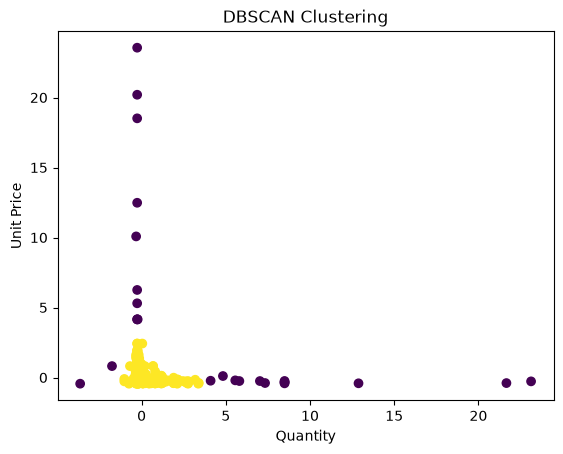

In [30]:
# Visualization
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels)
plt.xlabel('Quantity')
plt.ylabel('Unit Price')
plt.title('DBSCAN Clustering')
plt.show()

Important concepts
- eps = Maximum distance between nearby points.
- min_samples = Minimum points required to form a dense region.
- -1 = Noise point or outlier.
- fit_predict() = Train and assign cluster labels.

### Apriori Algorithm and Association Rule Mining

In [16]:
pip install mlxtend

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 1.5 MB/s eta 0:00:01
   -------------------------------------- - 1.3/1.4 MB 2.7 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 2.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\admin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [17]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

In [18]:
# Create transaction dataset
data = {
    'Milk': [1, 1, 0, 1, 0],
    'Bread': [1, 1, 1, 1, 0],
    'Butter': [0, 1, 1, 1, 1],
    'Eggs': [1, 0, 1, 1, 1]
}

In [19]:
df = pd.DataFrame(data)

In [20]:
# Frequent itemsets
frequent_items = apriori(
    df.astype(bool),
    min_support=0.4,
    use_colnames=True
)
print("Frequent Itemsets:")
print(frequent_items)

Frequent Itemsets:
    support                          itemsets
0       0.6                 frozenset({Milk})
1       0.8                frozenset({Bread})
2       0.8               frozenset({Butter})
3       0.8                 frozenset({Eggs})
4       0.6          frozenset({Bread, Milk})
5       0.4         frozenset({Butter, Milk})
6       0.4           frozenset({Eggs, Milk})
7       0.6        frozenset({Butter, Bread})
8       0.6          frozenset({Eggs, Bread})
9       0.6         frozenset({Butter, Eggs})
10      0.4  frozenset({Butter, Bread, Milk})
11      0.4    frozenset({Eggs, Bread, Milk})
12      0.4  frozenset({Butter, Eggs, Bread})


In [21]:
# Generate association rules
rules = association_rules(
    frequent_items,
    metric='confidence',
    min_threshold=0.5
)
print("Association Rules:")
print(rules)

Association Rules:
                   antecedents                 consequents  \
0            frozenset({Milk})          frozenset({Bread})   
1           frozenset({Bread})           frozenset({Milk})   
2          frozenset({Butter})           frozenset({Milk})   
3            frozenset({Milk})         frozenset({Butter})   
4            frozenset({Eggs})           frozenset({Milk})   
5            frozenset({Milk})           frozenset({Eggs})   
6          frozenset({Butter})          frozenset({Bread})   
7           frozenset({Bread})         frozenset({Butter})   
8            frozenset({Eggs})          frozenset({Bread})   
9           frozenset({Bread})           frozenset({Eggs})   
10         frozenset({Butter})           frozenset({Eggs})   
11           frozenset({Eggs})         frozenset({Butter})   
12   frozenset({Butter, Milk})          frozenset({Bread})   
13  frozenset({Butter, Bread})           frozenset({Milk})   
14    frozenset({Bread, Milk})         frozenset({B